Read about automatic differentation in "Machine Learning Defined" appendix B. You can find that online here
https://jermwatt.github.io/machine_learning_refined/notes/3_First_order_methods/3_5_Automatic.html
To make the module autograd available we use the following commands:

In [2]:
# import statement for autograd wrapped numpy
import autograd.numpy as np   
# import statment for gradient calculator
from autograd import grad  

Then we can use the following generic code for doing the gradient descent:

In [4]:
# import automatic differentiator to compute gradient module
from autograd import grad 

# gradient descent function - inputs: g (input function), alpha (steplength parameter), max_its (maximum number of iterations), w (initialization)
def gradient_descent(g,alpha,max_its,w):
    # compute gradient module using autograd
    gradient = grad(g)

    # run the gradient descent loop
    weight_history = [w]           # container for weight history
    cost_history = [g(w)]          # container for corresponding cost function history
    for k in range(max_its):
        # evaluate the gradient, store current weights and cost function value
        grad_eval = gradient(w)

        # take gradient descent step
        w = w - alpha*grad_eval
        
        # record weight and cost
        weight_history.append(w)
        cost_history.append(g(w))
    return cost_history

We now want to find the minimum of  

$$
g(w) = \frac{1}{50}\left(w^4 + w^2 + 10w\right)
$$

using the gradient descent method described above. Make three separate runs using step lengths  
$\alpha = 1$, $0.1$, and $0.01$, starting from $w^0 = 2$ with $1000$ iterations.  

Plot the resulting cost histories. Which step length works best for this particular function and initial point?


In [8]:
# defining g
g = lambda w: (w**4 + w**2 + 10*w) / 50

# parameters
alphas= [1, 0.1, 0.01]
w0 = 2.0
max_its = 1000

# cost histories
cost_histories_1 = gradient_descent(g,alphas[0],max_its,w0)
cost_histories_2 = gradient_descent(g,alphas[1],max_its,w0)
cost_histories_3 = gradient_descent(g,alphas[2],max_its,w0)

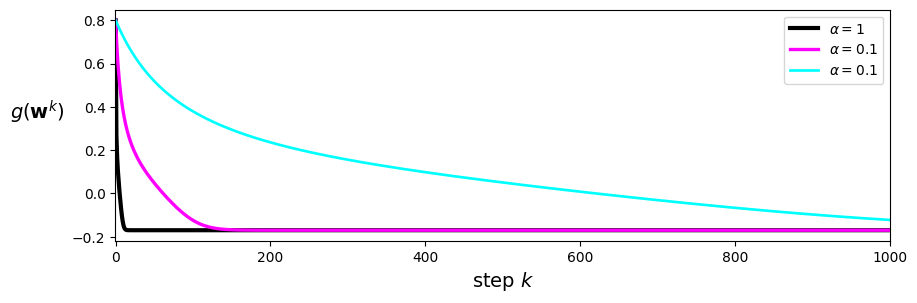

In [11]:
from MLRPlotting import static_plotter

# plotting the cost histories
from MLRPlotting import static_plotter

# import custom plotting tools
static_plotter = static_plotter.Visualizer()
static_plotter.plot_cost_histories([cost_histories_1,cost_histories_2,cost_histories_3],start=0,points=False,labels=[r'$\alpha = 1$',r'$\alpha = 0.1$',r'$\alpha = 0.01$'])

In [13]:
# minimum found for each alpha
print("Minimum found with alpha = 1: w* = ", np.round(np.array(cost_histories_1[-1]),4))
print("Minimum found with alpha = 0.1: w* = ", np.round(np.array(cost_histories_2[-1]),4))
print("Minimum found with alpha = 0.01: w* = ", np.round(np.array(cost_histories_3[-1]),4))

Minimum found with alpha = 1: w* =  -0.17
Minimum found with alpha = 0.1: w* =  -0.17
Minimum found with alpha = 0.01: w* =  -0.1225


both alpha = 1 and alpha = 0.1 reaches the minimum but alpha = 1 decreases faster.